In [12]:
import pandas as pd
import polars as pl
import ast
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pl.read_parquet("./weedvlm_scored_responses.parquet")

In [3]:
df = df.filter(pl.col("task") == "grounded_vqa").with_columns(
    pl.col("choices")
    .map_elements(ast.literal_eval, return_dtype=pl.List(pl.String))
)

The performance based purely on guessing is 42.74


(array([856., 355.,   0.,  75.,   0.,  39.,  14.,   0.,   5.,   5.]),
 array([2. , 2.6, 3.2, 3.8, 4.4, 5. , 5.6, 6.2, 6.8, 7.4, 8. ]),
 <BarContainer object of 10 artists>)

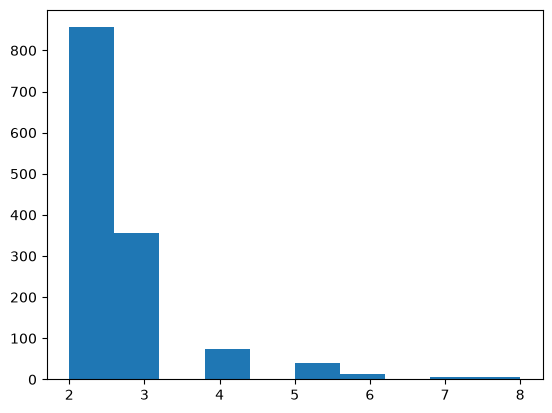

In [4]:
# What is the odds of guessing correct?
df = df.with_columns(
    pl.col("choices")
    .map_elements(lambda x: 1 / len(x))
    .alias("guess_chance")
)
df = df.with_columns(
    pl.col("choices")
    .map_elements(len)
    .alias("number_of_choices")
)
mean_guessing = df["guess_chance"].mean() * 100
print(f"The performance based purely on guessing is {mean_guessing:.2f}")
# Range of options
plt.hist(df["number_of_choices"])

In [5]:
# For grounded weed VQA, does the number of options correspond
print(df.group_by(["number_of_choices"]).agg(
    pl.col("match").mean().alias("accuracy") * 100,
    pl.len().alias("samples"),
)
.with_columns(
    (1 / pl.col("number_of_choices") * 100).alias("random_baseline")
)
.sort("number_of_choices")
)

shape: (7, 4)
┌───────────────────┬───────────┬─────────┬─────────────────┐
│ number_of_choices ┆ accuracy  ┆ samples ┆ random_baseline │
│ ---               ┆ ---       ┆ ---     ┆ ---             │
│ i64               ┆ f64       ┆ u32     ┆ f64             │
╞═══════════════════╪═══════════╪═════════╪═════════════════╡
│ 2                 ┆ 94.275701 ┆ 856     ┆ 50.0            │
│ 3                 ┆ 90.985915 ┆ 355     ┆ 33.333333       │
│ 4                 ┆ 86.666667 ┆ 75      ┆ 25.0            │
│ 5                 ┆ 79.487179 ┆ 39      ┆ 20.0            │
│ 6                 ┆ 57.142857 ┆ 14      ┆ 16.666667       │
│ 7                 ┆ 40.0      ┆ 5       ┆ 14.285714       │
│ 8                 ┆ 80.0      ┆ 5       ┆ 12.5            │
└───────────────────┴───────────┴─────────┴─────────────────┘


In [6]:
df = pl.read_parquet("./weedvlm_scored_responses.parquet")
df = df.filter(pl.col("task") == "localisation").with_columns(
    pl.col("boxes")
    .map_elements(ast.literal_eval, return_dtype=pl.List(pl.List(pl.Float64)))
)

In [7]:
# Parse these into relative areas [x1, y1, x2, y2]
df = df.with_columns(
    (pl.col("image_height") * pl.col("image_width")).alias("image_area")
)
def compute_box(box: list[float], total_area: float) -> float:
    width = box[2] - box[0]
    height = box[3] - box[1]
    return (width * height) / total_area

df = df.with_columns(
    pl.col("boxes")
    .list.eval(
        (
            (pl.element().list.get(2) - pl.element().list.get(0))
            *
            (pl.element().list.get(3) - pl.element().list.get(1))
        )
    )
    .truediv(pl.col("image_area"))
    .alias("relative_box_areas")
)

df = df.with_columns(
    pl.col("relative_box_areas").list.mean().alias("mean_relative_area"),
    pl.col("relative_box_areas").list.min().alias("min_relative_area"),
    pl.col("relative_box_areas").list.max().alias("max_relative_area"),
    pl.col("relative_box_areas").list.sum().alias("total_relative_area"),
)

In [8]:
# Does localisation performance deteriorate as the target weed occupies less of the image?
df = df.with_columns(
    pl.col("mean_relative_area")
    .bin_intervals(
        [0.01, 0.025, 0.05, 0.10],
        labels=["<1%", "1–2.5%", "2.5–5%", "5–10%", ">10%"]
    )
    .alias("area_group")
)
(
    df
    .group_by("area_group")
    .agg(
        pl.len().alias("n"),
        pl.col("localisation_score").mean(),
        pl.col("matched_iou").mean(),
    )
    .sort("area_group")
)

area_group,n,localisation_score,matched_iou
enum,u32,f64,f64
"""<1%""",429,0.380065,0.653361
"""1–2.5%""",74,0.354893,0.668873
"""2.5–5%""",105,0.315888,0.551904
"""5–10%""",141,0.39637,0.660942
""">10%""",344,0.270074,0.595522


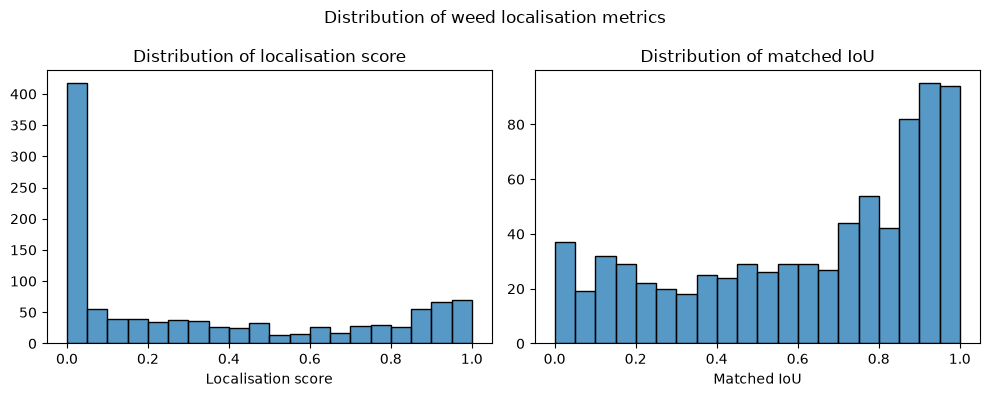

In [27]:
fig, axes = plt.subplots(1,2, figsize=(10,4))
fig.suptitle("Distribution of weed localisation metrics")
sns.histplot(
    df["localisation_score"], # type: ignore
    bins=20,
    ax=axes[0],
)
axes[0].set_xlabel("Localisation score")
axes[0].set_ylabel("")
axes[0].set_title("Distribution of localisation score")

sns.histplot(
    df["matched_iou"], # type: ignore
    bins=20,
    ax=axes[1],
)
axes[1].set_xlabel("Matched IoU")
axes[1].set_ylabel("")
axes[1].set_title("Distribution of matched IoU")
plt.tight_layout()
plt.show()

<Axes: ylabel='Count'>

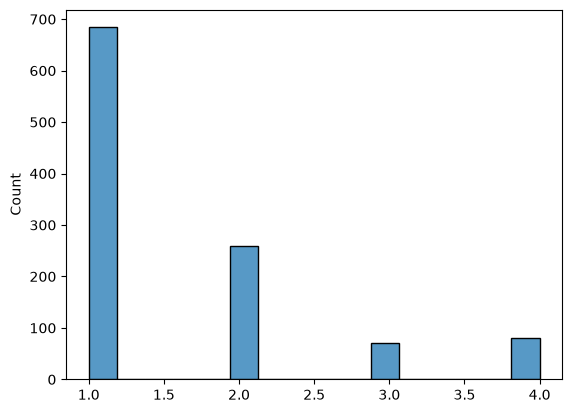

In [31]:
# Distribution of the number of boxes
df = df.with_columns(
    pl.col("boxes")
    .map_elements(len)
    .alias("number_of_boxes")
)
sns.histplot(df["number_of_boxes"])

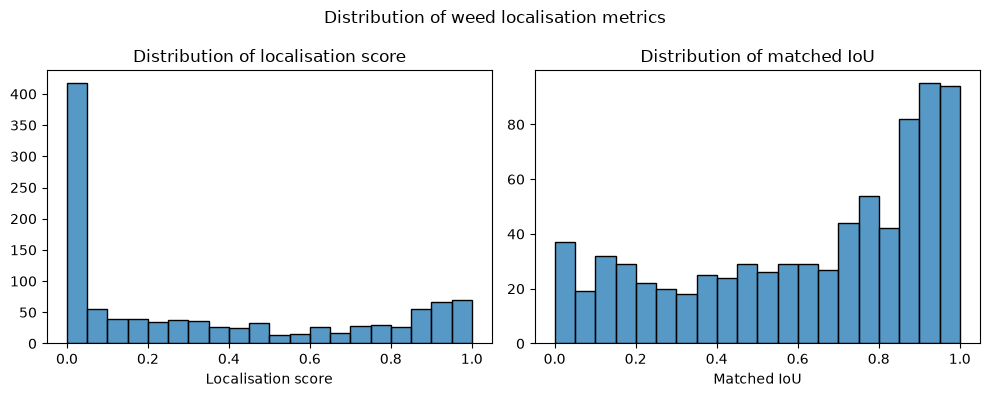

In [35]:
fig, axes = plt.subplots(1,2, figsize=(10,4))
fig.suptitle("Distribution of weed localisation metrics")
sns.histplot(
    df["localisation_score"], # type: ignore
    bins=20,
    ax=axes[0],
)
axes[0].set_xlabel("Localisation score")
axes[0].set_ylabel("")
axes[0].set_title("Distribution of localisation score")

sns.histplot(
    df["matched_iou"], # type: ignore
    bins=20,
    ax=axes[1],
)
axes[1].set_xlabel("Matched IoU")
axes[1].set_ylabel("")
axes[1].set_title("Distribution of matched IoU")
plt.tight_layout()
plt.show()

In [44]:
df = pl.read_parquet("./weedvlm_scored_responses.parquet")
df = df.filter(pl.col("task") == "density")
# For number of weeds
by_count = (
    df
    .group_by("true_weed_count")
    .agg(
        pl.col("count_error").abs().mean().alias("mae"),
        pl.len().alias("n"),
    )
    .sort("true_weed_count")
)
by_count = by_count.with_columns(
    (
        pl.col("mae") / pl.col("true_weed_count") * 100
    ).alias("relative_mae_pct")
)
by_count
# For 

true_weed_count,mae,n,relative_mae_pct
f64,f64,u32,f64
0.0,2.286031,451,inf
1.0,1.119522,251,111.952191
2.0,0.781818,55,39.090909
3.0,0.488372,43,16.27907
4.0,1.91954,87,47.988506
…,…,…,…
62.0,9.4,5,15.16129
63.0,23.555556,9,37.389771
71.0,24.75,8,34.859155


In [38]:
print(df.columns)

['id', 'run', 'model', 'question_id', 'status', 'answer', 'reasoning', 'parsed', 'raw_response', 'warnings', 'error_kind', 'error_message', 'error_http_status', 'attempts', 'retry_log', 'finish_reason', 'latency_seconds', 'usage', 'total_tokens', 'cost_usd', 'generation_id', 'provider', 'image_sha256', 'prompt_version', 'created_at', 'task', 'position', 'question_type', 'question_text', 'image_id', 'annotated', 'benchmark_class', 'dataset_name', 'source_image_id', 'annotation_ids', 'expected_answer', 'choices', 'answer_index', 'ablation_of', 'true_weed_count', 'true_weed_coverage_fraction', 'target_species', 'image_width', 'image_height', 'boxes', 'match', 'outcome', 'localisation_score', 'matched_iou', 'bbox_format', 'pred_boxes', 'est_count', 'est_coverage_pct', 'count_error', 'abs_count_error', 'coverage_error_pp', 'abs_coverage_error_pp']


<Axes: xlabel='true_weed_count', ylabel='abs_count_error'>

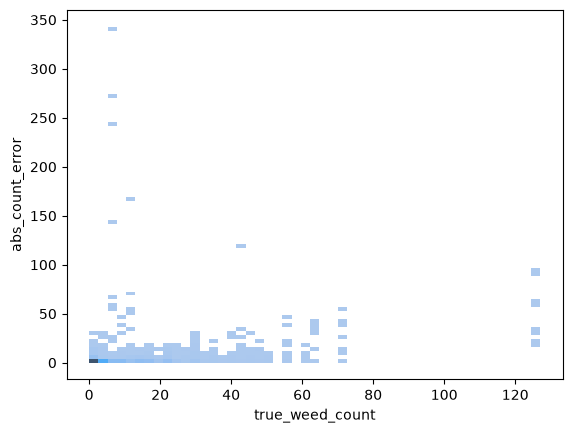

In [ ]:
sns.scatterplot(
    data=df.to_pandas(),
    x="true_weed_count",
    y="abs_count_error",
    alpha=0.3,
)

plt.xlabel("True weed count")
plt.ylabel("Absolute count error")
plt.title("Absolute count error vs. true weed count")

plt.show()